# World Happiness Report - Exploratory Data Analysis
**Author**: Jared Alviar

In [107]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import warnings
warnings.filterwarnings("ignore")

## High Level View

In [108]:
# Convert file into data frame
df = pd.read_csv("https://drive.google.com/uc?export=download&id=1PcCyXXs28wvhAcatjBqa48hf9JD8_Xqa")
df.head()


,Country,Region,Happiness Rank,Happiness Score,Lower Confidence Interval,Upper Confidence Interval,Economy (GDP per Capita),Family,Health (Life Expectancy),Freedom,Trust (Government Corruption),Generosity,Dystopia Residual
0,Denmark,Western Europe,1,7.526,7.460,7.592,1.44178,1.16374,0.79504,0.57941,0.44453,0.36171,2.73939
1,Switzerland,Western Europe,2,7.509,7.428,7.590,1.52733,1.14524,0.86303,0.58557,0.41203,0.28083,2.69463
2,Iceland,Western Europe,3,7.501,7.333,7.669,1.42666,1.18326,0.86733,0.56624,0.14975,0.47678,2.83137
3,Norway,Western Europe,4,7.498,7.421,7.575,1.57744,1.12690,0.79579,0.59609,0.35776,0.37895,2.66465
4,Finland,Western Europe,5,7.413,7.351,7.475,1.40598,1.13464,0.81091,0.57104,0.41004,0.25492,2.82596


This dataset contains World Happiness Report metrics across countries and geographic regions, ranking nations by overall Happiness Score alongside socioeconomic and institutional factors including GDP per capita, family support, life expectancy, freedom, government corruption, and generosity. In data science, it supports exploratory regional comparisons, correlation analysis, and predictive regression modeling of national well-being.

# Preliminary Exploration

In [109]:
# Preliminary Exploration 1
print(df.shape)
print("Duplicate rows:", df.duplicated().sum())
df.describe()

(157, 13)
Duplicate rows: 0


,Happiness Rank,Happiness Score,Lower Confidence Interval,Upper Confidence Interval,Economy (GDP per Capita),Family,Health (Life Expectancy),Freedom,Trust (Government Corruption),Generosity,Dystopia Residual
count,157.000000,157.000000,157.000000,157.000000,157.000000,157.000000,157.000000,157.000000,157.000000,157.000000,157.000000
mean,78.980892,5.382185,5.282395,5.481975,0.953880,0.793621,0.557619,0.370994,0.137624,0.242635,2.325807
std,45.466030,1.141674,1.148043,1.136493,0.412595,0.266706,0.229349,0.145507,0.111038,0.133756,0.542220
min,1.000000,2.905000,2.732000,3.078000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.817890
25%,40.000000,4.404000,4.327000,4.465000,0.670240,0.641840,0.382910,0.257480,0.061260,0.154570,2.031710
50%,79.000000,5.314000,5.237000,5.419000,1.027800,0.841420,0.596590,0.397470,0.105470,0.222450,2.290740
75%,118.000000,6.269000,6.154000,6.434000,1.279640,1.021520,0.729930,0.484530,0.175540,0.311850,2.664650
max,157.000000,7.526000,7.460000,7.669000,1.824270,1.183260,0.952770,0.608480,0.505210,0.819710,3.837720


The dataset contains 157 unique countries across 13 columns with 0 duplicate rows. Comparing means to medians (50%) shows that Happiness Score is well-balanced (mean 5.38, median 5.31), whereas Trust (Government Corruption) and Generosity are right-skewed with higher means than their medians and minimum values of 0.00 across six contributing factors.

Countries per Region:
Region
Sub-Saharan Africa                 38
Central and Eastern Europe         29
Latin America and Caribbean        24
Western Europe                     21
Middle East and Northern Africa    19
Southeastern Asia                   9
Southern Asia                       7
Eastern Asia                        6
North America                       2
Australia and New Zealand           2
Name: count, dtype: int64


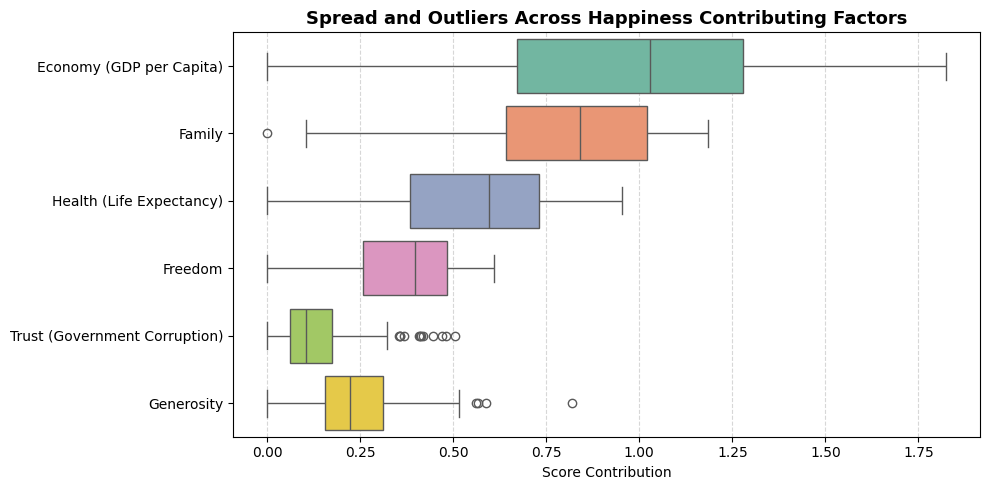

In [110]:
# Preliminary Exploration 2
# Check country counts per Region to identify representation imbalances
print("Countries per Region:")
print(df["Region"].value_counts())

# Plot horizontal boxplots of the six contributing factors
factors = [
    "Economy (GDP per Capita)",
    "Family",
    "Health (Life Expectancy)",
    "Freedom",
    "Trust (Government Corruption)",
    "Generosity",
]

plt.figure(figsize=(10, 5))
sns.boxplot(data=df[factors], orient="h", palette="Set2")
plt.title(
    "Spread and Outliers Across Happiness Contributing Factors",
    fontsize=13,
    fontweight="bold",
)
plt.xlabel("Score Contribution")
plt.grid(axis="x", linestyle="--", alpha=0.5)
plt.tight_layout()
plt.show()

- **Outliers & Spread**: Using the 1.5 x IQR rule and horizontal boxplots, Trust (Government Corruption) and Generosity show the heaviest right-skew and multiple high-end outliers, meaning a small group of countries scores far above the global norm in institutional trust and charitable giving. Meanwhile, Family shows a few low-end outliers, while Economy, Health, and Freedom are more evenly spread within their interquartile ranges.
- **Data Quality Issues**: Beyond regional sample imbalances (where regions like Sub-Saharan Africa and Central/Eastern Europe contain far more listed nations than North America or Australia and New Zealand), the dataset has zero missing values, zero duplicates, and clean numerical formatting. The 0.00 minimums represent valid floor baselines rather than corrupted entries.

## 3. Defining Objectives
1. **Regional Happiness Score Comparison:** How does the average **Happiness Score** compare across different global **Regions**, and which regions lead or trail the global average?
2. **Primary Contributors Among the Happiest Nations:** Among the top 25% happiest countries, which contributing factors drive well-being most strongly, and how consistent are they?
3. **Social Support vs. Life Expectancy Across Happiness Tiers:** How strongly do **Family (social support)** and **Health (Life Expectancy)** move together across nations segmented into Low, Medium, and High happiness tiers?

### Objective 1: Regional Happiness Score Comparison
**Plot Justification:** A sorted horizontal bar chart prevents long region names from overlapping and makes ranking differences immediately readable alongside a dashed vertical line marking the global average (5.38).

,Region,Happiness Score
0,Australia and New Zealand,7.323500
1,North America,7.254000
2,Western Europe,6.685667
3,Latin America and Caribbean,6.101750
4,Eastern Asia,5.624167
5,Middle East and Northern Africa,5.386053
6,Central and Eastern Europe,5.370690
7,Southeastern Asia,5.338889
8,Southern Asia,4.563286
9,Sub-Saharan Africa,4.136421


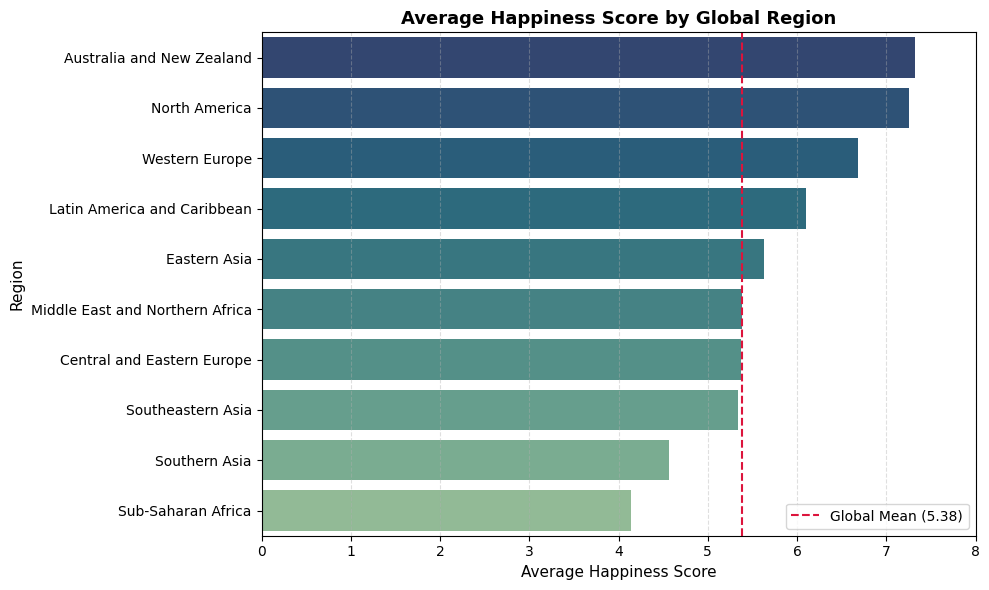

In [111]:
# Objective 1: How does the average Happiness Score compare across different global Regions?

# Group by Region and calculate mean Happiness Score (sorted highest to lowest)
regional_happiness = (
    df.groupby("Region")["Happiness Score"]
    .mean()
    .sort_values(ascending=False)
    .reset_index()
)

display(regional_happiness)

# Calculate global average for the reference line
global_mean = df["Happiness Score"].mean()

# Create horizontal bar chart
plt.figure(figsize=(10, 6))
sns.barplot(
    data=regional_happiness,
    x="Happiness Score",
    y="Region",
    hue="Region",
    palette="crest_r",
    legend=False,
)

# Add dashed vertical line showing the global mean
plt.axvline(
    global_mean,
    color="crimson",
    linestyle="--",
    linewidth=1.5,
    label=f"Global Mean ({global_mean:.2f})",
)

plt.title(
    "Average Happiness Score by Global Region", fontsize=13, fontweight="bold"
)
plt.xlabel("Average Happiness Score", fontsize=11)
plt.ylabel("Region", fontsize=11)
plt.xlim(0, 8)
plt.legend()
plt.grid(axis="x", linestyle="--", alpha=0.4)
plt.tight_layout()
plt.show()

**Results & Conclusion**: Looking at the horizontal bar chart, global well-being separates into three distinct regional tiers relative to the Global Mean (5.38)
- **Above-Average Leaders**: Australia and New Zealand (7.32) and North America (7.25) sit clearly at the top, followed by Western Europe (6.69), Latin America and Caribbean (6.10), and Eastern Asia (5.62) all extending noticeably past the dashed global average line.   
- **Middle Cluster (Near the Global Mean)**: Middle East and Northern Africa, Central and Eastern Europe, and Southeastern Asia all cluster right along the 5.38 global mean, showing virtually identical average happiness scores.   
- **Below-Average Regions**: Southern Asia (4.56) and Sub-Saharan Africa (4.14) fall well below the global benchmark, trailing the top-ranking regions by more than three full points on the 10-point scale.

### Objective 2: Primary Contributors Among the Happiest Nations
**Plot Justification:** Side-by-side boxplots clearly display the median, interquartile range (IQR), and potential outliers for all six contributing factors simultaneously across the top 25% happiest nations (n = 39).

,Median,IQR
Economy (GDP per Capita),1.40283,0.258365
Family,1.04477,0.106020
Health (Life Expectancy),0.80315,0.109750
Freedom,0.51354,0.129100
Generosity,0.28808,0.195365
Trust (Government Corruption),0.21348,0.228310


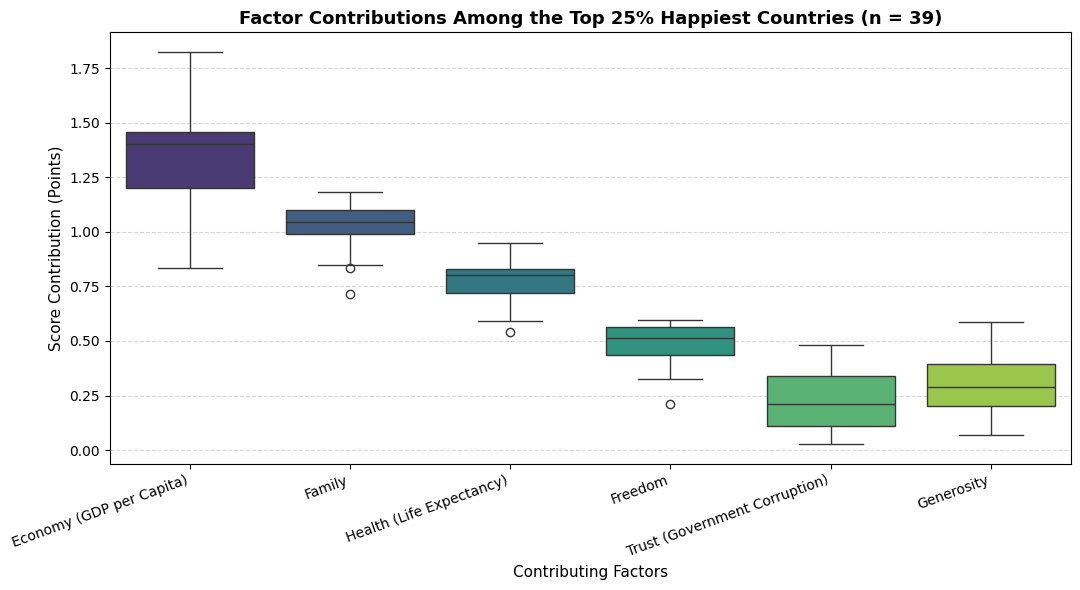

In [112]:
# Objective 2: Primary Contributors Among the Happiest Nations

# Filtering the top 25% of the happiest countries
top_25_filter = df[df["Happiness Score"] > df["Happiness Score"].quantile(0.75)]

# Listing all the contributing factors
factors = [
    "Economy (GDP per Capita)",
    "Family",
    "Health (Life Expectancy)",
    "Freedom",
    "Trust (Government Corruption)",
    "Generosity",
]

#Print median and IQR for exact numerical comparison
summary_stats = pd.DataFrame({
    "Median": top_25_filter[factors].median(),
    "IQR": (
        top_25_filter[factors].quantile(0.75)
        - top_25_filter[factors].quantile(0.25)
    ),
}).sort_values(by="Median", ascending=False)

display(summary_stats)

# Plot in a box plot
plt.figure(figsize=(11, 6))
sns.boxplot(data=top_25_filter[factors], palette="viridis", showmeans=False)

plt.title(
    "Factor Contributions Among the Top 25% Happiest Countries (n = 39)",
    fontsize=13,
    fontweight="bold",
)
plt.ylabel("Score Contribution (Points)", fontsize=11)
plt.xlabel("Contributing Factors", fontsize=11)
plt.xticks(rotation=20, ha="right")
plt.grid(axis="y", linestyle="--", alpha=0.5)
plt.tight_layout()
plt.show()

**Inference & Conclusion**: Looking at the box plots, Economy (GDP per Capita), Family, and Health (Life Expectancy) are clearly the top three contributors to overall well-being among the happiest countries, showing both the highest median scores and relatively tight interquartile ranges. Freedom sits consistently in the middle tier with a narrow spread, acting as a steady supporting factor across top-performing nations. Surprisingly, Generosity and Trust (Government Corruption) sit near the bottom with much lower medians, contrary to the initial expectation that higher generosity would be a primary driver of happiness. Together, these patterns suggest that strong economic stability, social support, and health form the core foundation of top-tier happiness, supported steadily by personal freedom, while generosity and institutional trust play smaller, secondary roles.

### Objective 3: Social Support vs. Life Expectancy Across Happiness Tiers
**Plot Justification:** A hue-grouped scatterplot effectively reveals both the overall bivariate correlation between Family and Health and how tightly countries cluster within each "Happiness Tier" (Low, Medium, High).

Pearson Correlation (Family vs. Health): 0.588



,Family,Health (Life Expectancy)
Happiness Tier,,
Low,0.615860,0.29981
Medium,0.824790,0.61853
High,1.032225,0.77067


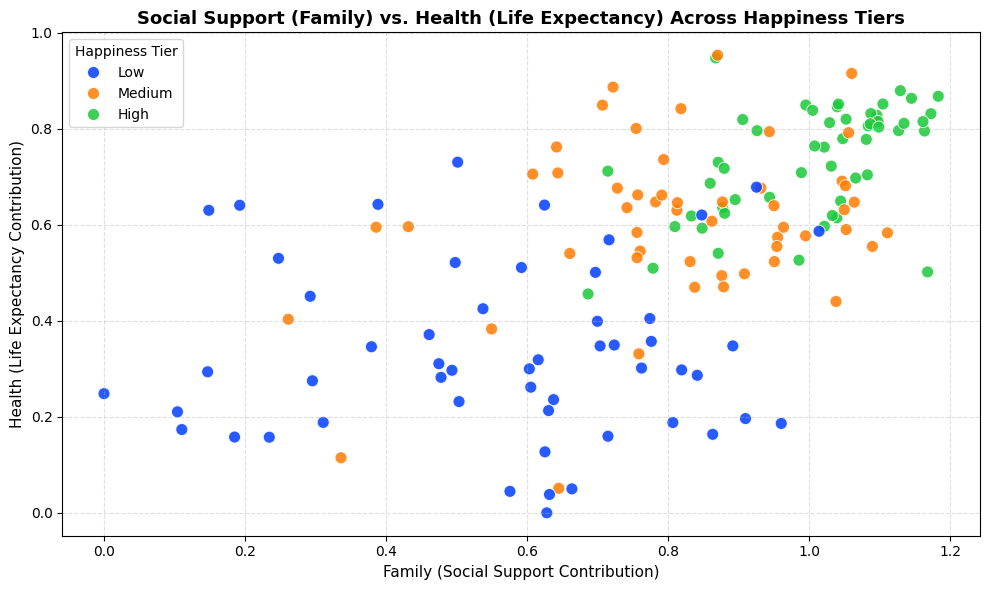

In [113]:
# Objective 3: How strongly do Family (social support) and Health (Life Expectancy) move together across nations?

# Split the happiness scores into three tiers
happiness_tiers = pd.qcut(df["Happiness Score"], q=3, labels=["Low", "Medium", "High"])
df_with_tiers = df.copy()
df_with_tiers.insert(4, "Happiness Tier", happiness_tiers)
df_with_tiers.head()

# Print Pearson correlation and tier medians for exact reference
corr = df_with_tiers["Family"].corr(df_with_tiers["Health (Life Expectancy)"])
print(f"Pearson Correlation (Family vs. Health): {corr:.3f}\n")
display(
    df_with_tiers.groupby("Happiness Tier", observed=False)[
        ["Family", "Health (Life Expectancy)"]
    ].median()
)

# Plot the grouped scatterplot
plt.figure(figsize=(10, 6))
sns.scatterplot(
    data=df_with_tiers,
    x="Family",
    y="Health (Life Expectancy)",
    hue="Happiness Tier",
    palette="bright",
    s=75,
    alpha=0.85,
)

plt.title(
    "Social Support (Family) vs. Health (Life Expectancy) Across Happiness Tiers",
    fontsize=13,
    fontweight="bold",
)
plt.xlabel("Family (Social Support Contribution)", fontsize=11)
plt.ylabel("Health (Life Expectancy Contribution)", fontsize=11)
plt.legend(title="Happiness Tier")
plt.grid(True, linestyle="--", alpha=0.4)
plt.tight_layout()
plt.show()

**Results & Conclusion**: Looking at the scatterplot across all 157 countries, Family (social support) and Health (Life Expectancy) show an overall positive upward trend moving from the bottom-left to the top-right. However, breaking the countries into Happiness Tiers reveals a clear difference in how tightly they cluster:
- **Low Tier (Blue)**: There is virtually no correlation within this group, the points scatter widely across low-to-moderate family scores while life expectancy stays low, showing that strong family ties alone do not guarantee higher health outcomes in lower-scoring nations.
- **Medium Tier (Orange) & High Tier (Green)**: As happiness increases, the points compress into much tighter clusters toward the upper-right quadrant, showing that countries in the highest happiness tier consistently pair strong social support (> 0.85) with high life expectancy (> 0.65).

# Ethical Considerations & Data Limitations
While the World Happiness Report provides useful high-level insights into global well-being, applying these findings responsibly requires accounting for several methodological and ethical limitations:
- **Cultural & Measurement Bias**: Happiness scores rely on self-reported survey responses where respondents rate their lives on a 0–10 "ladder." Cultural norms strongly influence how people interpret and answer subjective well-being questions, some cultures emphasize individual achievement and optimism, while others value modesty or community harmony, meaning identical numeric scores may not reflect identical lived experiences across all the participants.
- **Regional Sample Size Imbalances & Selection Bias**: Regional averages treat every region equally on a chart, even though sample sizes vary dramatically (for example, North America and Australia and New Zealand contain only 2 countries each, whereas Sub-Saharan Africa spans 38 diverse nations). Additionally, countries experiencing severe conflict, political instability, or limited polling infrastructure may be underrepresented or excluded altogether, skewing regional comparisons.
- **Correlation vs. Causation in Policy Decisions**: Our visualizations show strong associations, such as top-tier nations clustering around higher Economy (GDP per Capita), Family, and Health scores, but observational survey data cannot prove direct causation. Policymakers who treat these additive factor decompositions as a rigid formula risk over-prioritizing short-term GDP growth at the expense of mental health, environmental sustainability, or equity for marginalized groups masked by national averages.
- **Privacy & Responsible Aggregation**: Although country-level averages protect individual survey respondents from direct re-identification, reducing entire populations to a single national rank can reinforce harmful regional stereotypes (such as labeling entire regions as "unhappy") if decision-makers ignore within-country inequality and local context.